In [1]:
# Titanic Survival Prediction Using Random Forest & Feature Engineering

## 1. Project Overview
##This notebook walks through an end-to-end machine learning workflow to predict passenger survival on the Titanic. We transition from basic data exploration to advanced feature engineering and an ensemble classifier (Random Forest) to maximize predictive performance.

In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
data_path = os.path.join("..", "data", "train.csv") # Use "data/train.csv" if running from root
if not os.path.exists(data_path):
    data_path = os.path.join("data", "train.csv")

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
## 2. Feature Engineering
#Raw text data like passenger names and family counts contain critical latent signals. We extract social titles (`Mr`, `Mrs`, `Miss`, `Master`, `Rare`), compute total `FamilySize`, and create an `IsAlone` binary flag.

In [4]:
def extract_title(name):
    title_search = re.search(r' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return "Unknown"

df['Title'] = df['Name'].apply(extract_title)
rare_titles = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

print(df[['Name', 'Title', 'FamilySize', 'IsAlone']].head())

                                                Name Title  FamilySize  \
0                            Braund, Mr. Owen Harris    Mr           2   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs           2   
2                             Heikkinen, Miss. Laina  Miss           1   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs           2   
4                           Allen, Mr. William Henry    Mr           1   

   IsAlone  
0        0  
1        0  
2        1  
3        0  
4        1  


In [5]:
## 3. Preprocessing, Pipeline Setup, and Training
#We use scikit-learn's `ColumnTransformer` and `Pipeline` to impute missing values (medians for numerical features) and apply `OneHotEncoder` to categorical features (`Sex`, `Title`), preventing any data leakage. We then train a tuned `RandomForestClassifier`.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

features = ['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize', 'IsAlone']
target = 'Survived'

X = df[features]
y = df[target]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = ['Pclass', 'Age', 'Fare', 'FamilySize', 'IsAlone']
categorical_features = ['Sex', 'Title']

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median'))]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
])

clf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=3, random_state=42, class_weight='balanced'))
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_val)

print(f"Accuracy:  {accuracy_score(y_val, y_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_pred):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_val, y_pred))

Accuracy:  0.8212
Precision: 0.7606
Recall:    0.7826
F1-Score:  0.7714

Confusion Matrix:
 [[93 17]
 [15 54]]


In [7]:
## 4. Feature Importance Analysis
#We extract the feature importances from the trained Random Forest to evaluate which variables drove predictions.

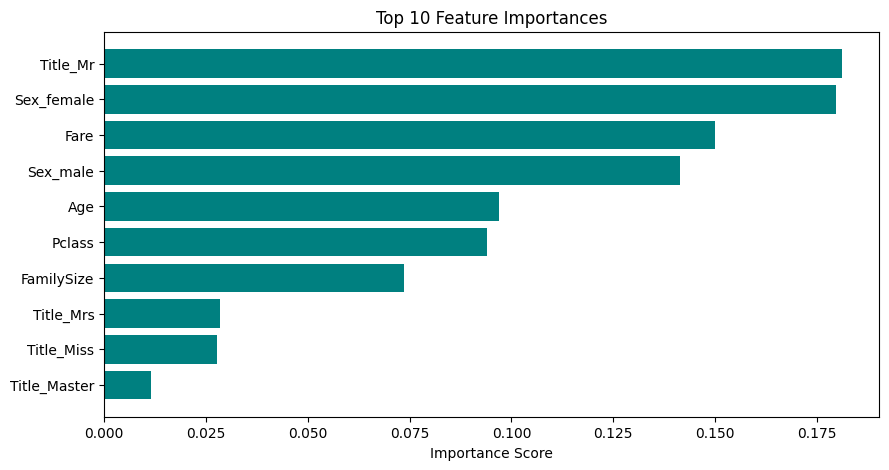

In [8]:
cat_encoder = clf.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
all_feature_names = numeric_features + list(cat_encoder.get_feature_names_out(categorical_features))
importances = clf.named_steps['classifier'].feature_importances_

fi_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(fi_df['Feature'].head(10), fi_df['Importance'].head(10), color='teal')
plt.xlabel('Importance Score')
plt.title('Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.show()